# Biến đổi Hough đa tỉ lệ

In [74]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

In [75]:
def p(theta, x, y):
    return x * np.cos(theta) + y * np.sin(theta)

In [76]:
np.cos(np.pi/2)

np.float64(6.123233995736766e-17)

In [77]:
x = 5
y = 3
delta_theta = np.linspace(0, np.pi, 180)


In [78]:
img = cv.imread("anhTest.jpg", cv.IMREAD_GRAYSCALE)

In [79]:
H, W = img.shape
H


300

In [80]:
def convol2d(img: np.ndarray, kernel: np.ndarray, stride: int = 1, padding: int=0):
        try:
            #kernel = np.flipud(np.fliplr(kernel)),
    
            image_height, image_weight = img.shape 
            kernel_height, kernel_weight = kernel.shape 
    
            out_heigh = int(np.floor(image_height - kernel_height + 2 * padding) / stride) +1
            out_weight= int(np.floor(image_weight - kernel_weight + 2 * padding) / stride) +1
    
            out = np.zeros((out_heigh, out_weight))
    
            for h in range(out_heigh):
                for w in range(out_weight):
                    out[h][w] = (img[h : h + kernel_height, w : w + kernel_weight] * kernel).sum()
    
            return out
        
        except ValueError as e:
            print("Error: " , e)
            return None

## tìm cạnh

In [81]:
def D(H, W):
    return np.sqrt(np.pow(H, 2) + np.pow(W, 2))

In [82]:
t_lower = 30  
t_upper = 100 
edges = cv.Canny(img, t_lower, t_upper)
edges

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(300, 300), dtype=uint8)

## Xây dựng hàm

In [83]:
def p(x, y, Theta):
    return x * np.cos(Theta) + y * np.sin(Theta)

In [84]:
theta_range = np.deg2rad(np.arange(0, 180, 1))
rho_range = np.arange(-1 * D(H, W), D(H, W), 1)

In [ ]:
def hough_accumulate(edges : np.ndarray, theta_range, rho_range, n_theta, n_rho,
                     grad_dir=None, delta_deg=None):
    """Bỏ phiếu vào mảng tích lũy. Nếu grad_dir khác None, chỉ bỏ phiếu
    trong dải +/- delta_deg quanh hướng gradient.
    Trả về (A, thetas, rhos)."""
    y, x = np.where(edges > 0)

    # A is a coarse resolution accumulate array
    A = np.zeros((n_rho, n_theta)) 

    delta_rho = 1 

    cos_theta = np.cos(theta_range)
    sin_theta = np.sin(theta_range)

    for i in range(len(x)):
        xi = x[i]
        yi = y[i]

        for j in range(n_theta):
            rho = int((xi * cos_theta[j] +
                       yi * sin_theta[j] + np.ceil(D(H, W))
                       ))
            A[rho, j] += 1
    return A, theta_range, rho_range
    
    

In [ ]:
def find_peaks(A, n_peaks, nms_radius=3, smooth_sigma=1.0):
    """Làm mượt A bằng hàm tích chập của chính nhóm, triệt phi cực đại,
    trả về danh sách (rho, theta, votes) sắp giảm dần."""
    Kernel = np.ones((3, 3))/9
    A_soft = convol2d(A, Kernel)
    indicies = []
    
    for i in range(n_peaks):
        idx = np.argmax(A_soft) # find argmax in flattened array
        A_soft_idx = np.unravel_index(idx, A_soft.shape) # remap to shape of A_soft
        indicies.append(A_soft_idx)

        # surpess indicies in neighborhood
        idx_y, idx_x = A_soft_idx # first separate x, y indexes from argmax(H)
        # if idx_x is too close to the edges choose appropriate values
        if (idx_x - (nms_radius/2)) < 0: min_x = 0
        else: min_x = idx_x - (nms_radius/2)
        if ((idx_x + (nms_radius/2) + 1) > A.shape[1]): max_x = A.shape[1]
        else: max_x = idx_x + (nms_radius/2) + 1

        # if idx_y is too close to the edges choose appropriate values
        if (idx_y - (nms_radius/2)) < 0: min_y = 0
        else: min_y = idx_y - (nms_radius/2)
        if ((idx_y + (nms_radius/2) + 1) > A.shape[0]): max_y = A.shape[0]
        else: max_y = idx_y + (nms_radius/2) + 1

        # bound each index by the neighborhood size and set all values to 0
        for x in range(min_x, max_x):
            for y in range(min_y, max_y):
                # remove neighborhoods in img
                A_soft[y, x] = 0

                # highlight peaks in original H
                if (x == min_x or x == (max_x - 1)):
                    A[y, x] = 255
                if (y == min_y or y == (max_y - 1)):
                    A[y, x] = 255

    # return the indicies and the original Hough space with selected points
    return indicies, A[0], A[1]
        
    

In [ ]:
def hough_multiscale(edges, grad_dir, n_levels=2, refine_factor=8):
    """Hough thô-đến-mịn. Trả về danh sách (rho, theta) đã tinh chỉnh."""
    for level in range(n_levels):
        # downsample the image for the current level
        scale_factor = 1 / (refine_factor ** level) # Delta Theta / r**n_level
        scaled_edges = cv.resize(edges, (0, 0), fx=scale_factor, fy=scale_factor)

        A, theta_range, rho_range = hough_accumulate(scaled_edges, theta_range, rho_range, len(theta_range), len(rho_range))

        # find peaks in the Hough space
        peaks, _, _ = find_peaks(A, n_peaks=10)

        # refine the peaks to the original scale
        refined_peaks = [(int(rho / scale_factor), theta) for rho, theta in peaks]
    
    return refined_peaks[0], refined_peaks[1]
    
    

## Đối chiếu

In [95]:
from scipy.signal import find_peaks
peaks, _ = find_peaks(hough_accumulator.flatten(), height=0)
peaks


array([ 25199,  25378,  25558, ..., 136683, 136687, 136863],
      shape=(12403,))

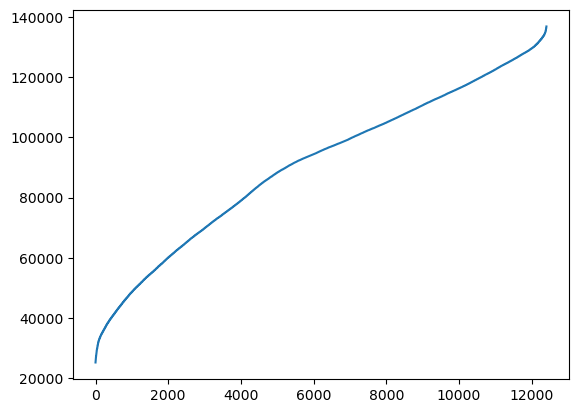

In [96]:
plt.plot(peaks)